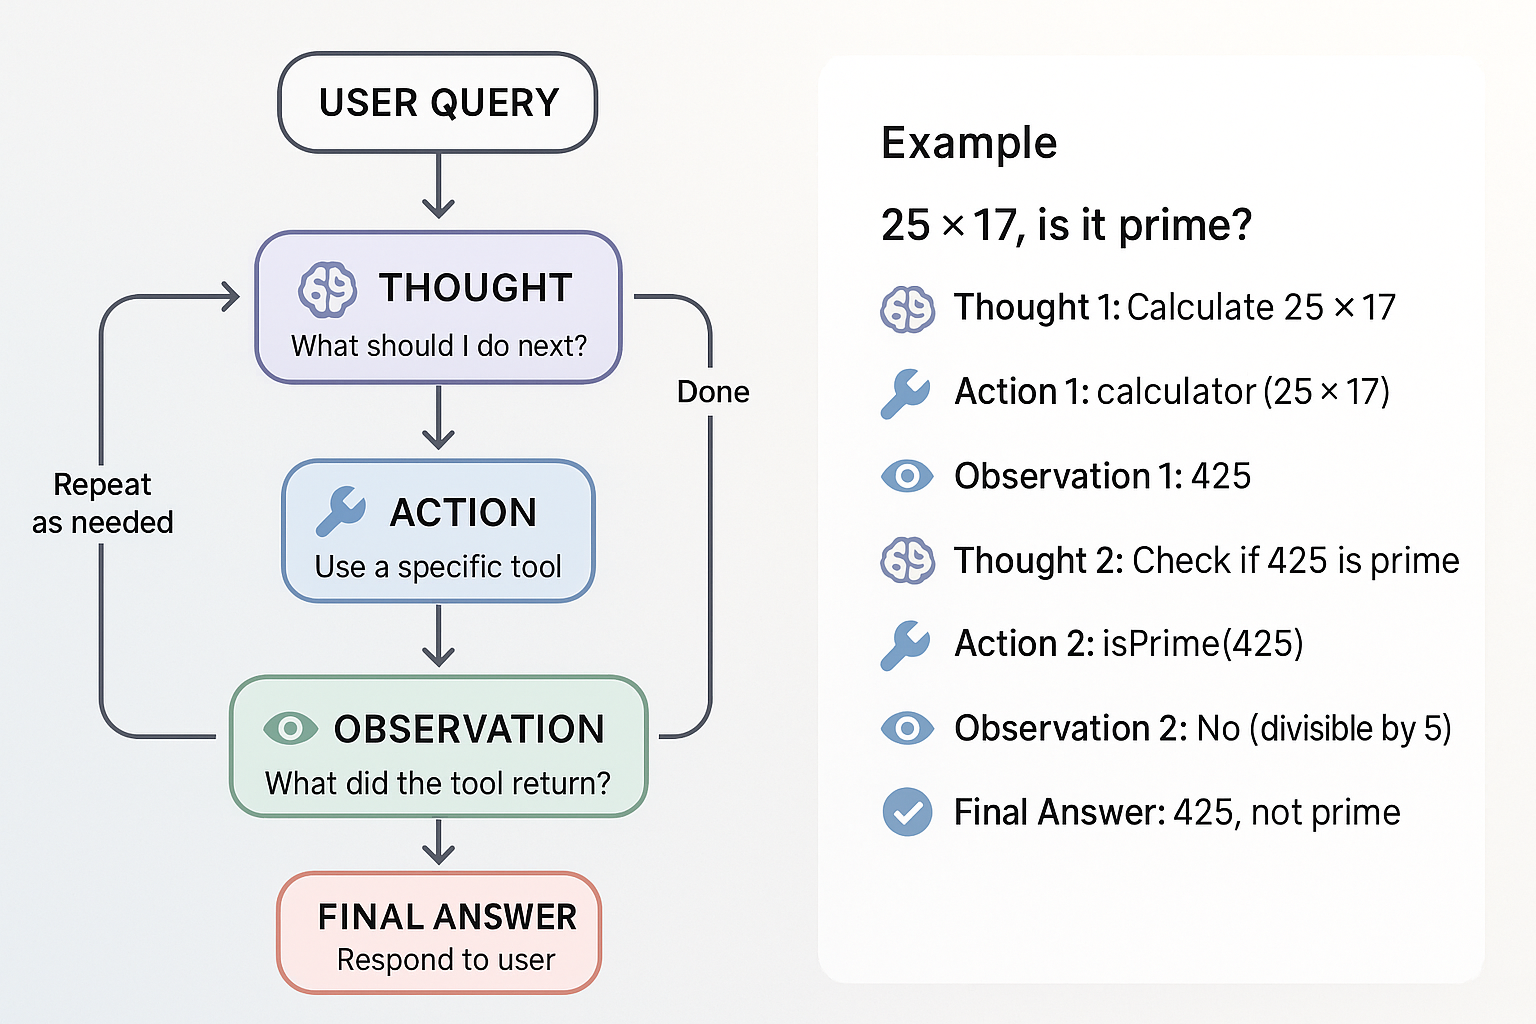

In [2]:
from dotenv import load_dotenv
load_dotenv()

True

### Building Agents with create_agent()
LangChain Python provides create_agent() from langchain.agents - a high-level API that handles the ReAct loop automatically. This is the recommended approach for building production agents.

What create_agent() does for you:

- ✅ Manages the ReAct loop (Thought → Action → Observation → Repeat)
- ✅ Handles message history automatically
- ✅ Implements iteration limits to prevent infinite loops
- ✅ Provides production-ready error handling
- ✅ Returns clean, structured responses

### Example 1: Basic Agent with create_agent()
- Let's see how to use create_agent() to create an autonomous agent that handles the ReAct loop (Thought → Action → Observation) automatically.



In [4]:
from langchain_groq import ChatGroq
from langchain_core.tools import tool
from langchain.agents import create_agent
from pydantic import BaseModel, Field
from langchain.messages import HumanMessage

class calculatorinlput(BaseModel):
    """Input for calculator tool."""
    expression: str = Field(
        description="Evaluating Mathematical expression, e.g. '2 * 5'"
            )

@tool(args_schema=calculatorinlput)
def calculator(expression: str) -> str:
    """A calculator that can perform basic arithmetic operations.
    Use this when you need to calculate mathematical expressions."""
    try: 
        allowed_names = {
            "min" : min,
            "max" : max,
            "sum" : sum,
            "pow" : pow,
            "abs" : abs,
            "round" : round
        }

        result = eval(expression, {"__builltins__": {}},allowed_names)
        return str(result)
    except Exception as e:
        return f"Error: {e}"



def main():
    print("Agent with create_agent() Example\n")

    model = ChatGroq(
        model="openai/gpt-oss-120b",
        temperature=0

    )

    agent = create_agent(
        model=model,
        tools=[calculator]
    )


    query = "What is 2013/15 * 24?"
    print(f"query: {query}\n")
    
    response = agent.invoke({"messages": [HumanMessage(content=query)]})

    # The response contains the full state, including all messages
    # Get the last message which is the agent's final answer
    last_message = response["messages"][-1]
    print(f"agent: {last_message.content}")


    print("Key Differences from Manual Loop:")
    print("• create_agent() handles the ReAct loop automatically")
    print("• Less code to write")
    print("• Production-ready error handling built-in")
    print("• Same result, simpler API\n")

    print("Under the hood:")
    print("create_agent() implements the ReAct pattern (Thought → Action → Observation)")
    print("and handles all the boilerplate for you.")


if __name__ == "__main__":
    main()    


Agent with create_agent() Example

query: What is 2013/15 * 24?

agent: \( \displaystyle \frac{2013}{15} \times 24 = \frac{2013 \times 24}{15} = \frac{2013 \times 8}{5} = \frac{16104}{5} = 3220.8 \)

So the result is **3220.8**.
Key Differences from Manual Loop:
• create_agent() handles the ReAct loop automatically
• Less code to write
• Production-ready error handling built-in
• Same result, simpler API

Under the hood:
create_agent() implements the ReAct pattern (Thought → Action → Observation)
and handles all the boilerplate for you.


### Example 2: create_agent() with Multiple Tools
Let's see how to give an agent multiple tools using tools=[tool1, tool2, tool3] and observe how it autonomously selects the right one.

In [6]:
from langchain_groq import ChatGroq
from langchain_core.tools import tool
from langchain.agents import create_agent
from pydantic import BaseModel, Field
from langchain.messages import HumanMessage


class CalculatorInput(BaseModel):
    """Input for calculator."""

    expression: str = Field(description="The mathematical expression to evaluate")


class WeatherInput(BaseModel):
    """Input for weather."""

    city: str = Field(description="The name of the city to get weather for")


class SearchInput(BaseModel):
    """Input for search."""

    query: str = Field(description="The search query")


@tool(args_schema=CalculatorInput)
def calculator(expression: str) -> str:
    """Perform mathematical calculations. Use this for arithmetic operations."""
    try:
        result = eval(expression, {"__builtins__": {}}, {})
        return f"The result is: {result}"
    except Exception as e:
        return f"Error: {e}"


@tool(args_schema=WeatherInput)
def get_weather(city: str) -> str:
    """Get current weather information for a specific city."""
    # Simulated weather data
    weather = {
        "Seattle": "62°F, cloudy with a chance of rain",
        "Paris": "18°C, sunny and pleasant",
        "Tokyo": "24°C, rainy with occasional thunder",
        "New York": "70°F, partly cloudy",
        "London": "15°C, foggy with light drizzle",
    }

    city_weather = weather.get(city)
    if city_weather:
        return f"Current weather in {city}: {city_weather}"
    return f"Weather data unavailable for {city}"



@tool(args_schema=SearchInput)
def search(query: str) -> str:
    """Search for information on the web. Use this for general knowledge questions."""
    # Simulated search results
    search_results = {
        "langchain": "LangChain is a framework for building applications with large language models (LLMs). It provides tools, agents, chains, and memory systems to create sophisticated AI applications.",
        "typescript": "TypeScript is a strongly typed programming language that builds on JavaScript, giving you better tooling at any scale.",
        "javascript frameworks": "Popular JavaScript frameworks include React, Vue, Angular, Svelte, and Next.js for building modern web applications.",
    }

    # Find best match (simplified)
    query_lower = query.lower()
    for key, value in search_results.items():
        if key in query_lower:
            return f'Search results for "{query}": {value}'

    return f'Search results for "{query}": Found information about web development, programming, and related topics.'


def main():
    llm = ChatGroq(
        model="openai/gpt-oss-120b",
        temperature=0

    )

    agent = create_agent(
        model=llm,
        tools=[calculator,get_weather,search]
    )    


    # Test with different queries - agent selects the right tool automatically
    queries = [
        "What is 50 * 25?",
        "What's the weather in Tokyo?",
        "Tell me about LangChain",
    ]

    for query in queries:
        print(f"query: {query}\n")
        response1 = agent.invoke({"messages": [HumanMessage(content=query)]})
        last_message = response1["messages"][-1]
        print(f"agent: {last_message.content}\n")



    print("  What just happened:")
    print("   • The agent automatically selected the right tool for each query")
    print("   • Calculator for math (50 * 25)")
    print("   • Weather tool for Tokyo weather")
    print("   • Search tool for LangChain information")
    print("   • All with the same agent instance!\n")

    print("  Production Pattern:")
    print("   This is how you build real-world agents:")
    print("   1. Define your tools")
    print("   2. Pass them to create_agent()")
    print("   3. Let the agent handle tool selection and execution")


if __name__ == "__main__":
    main()

query: What is 50 * 25?

agent: 50 × 25 = **1,250**.

query: What's the weather in Tokyo?

agent: The current weather in Tokyo is **24 °C** with **rain and occasional thunder**. Stay dry!

query: Tell me about LangChain

agent: **LangChain – an Overview**

---

### What Is LangChain?

LangChain is an open‑source **framework for building applications powered by large language models (LLMs)** such as OpenAI’s GPT‑4, Anthropic’s Claude, Llama 2, Gemini, and many others.  
Instead of treating an LLM as a single “black‑box” API call, LangChain gives you the building blocks to **orchestrate multiple calls, combine them with external data, and add logic, memory, and control flow**—essentially turning a raw LLM into a full‑featured software component.

---

### Core Concepts & Building Blocks

| Block | What It Does | Typical Use |
|-------|--------------|-------------|
| **PromptTemplates** | Structured, reusable prompt strings with variable interpolation. | Keep prompts DRY and version‑contr

### Agent with memory

In [7]:
from dotenv import load_dotenv
from langchain.agents import create_agent
from langchain_core.messages import HumanMessage
from langchain_core.tools import tool
from langchain_openai import ChatOpenAI
from pydantic import BaseModel, Field
from langgraph.checkpoint.memory import MemorySaver




class CalculatorInput(BaseModel):
    """Input for calculator."""

    expression: str = Field(description="The mathematical expression to evaluate")


class SearchInput(BaseModel):
    """Input for search."""

    query: str = Field(description="The search query")


@tool(args_schema=CalculatorInput)
def calculator_2(expression: str) -> str:
    """Perform mathematical calculations."""
    try:
        result = eval(expression, {"__builtins__": {}}, {})
        return f"The result is: {result}"
    except Exception as e:
        return f"Error: {e}"


@tool(args_schema=SearchInput)
def search_2(query: str) -> str:
    """Search for information."""
    # Simulate occasional failures for demonstration
    if "error" in query.lower():
        raise Exception("Search service temporarily unavailable")

    return f'Search results for "{query}": Found relevant information about {query}.'



def main():
    print("🔧 Agent with Memory (Checkpointer) Example\n")

    llm2 = ChatGroq(
        model="openai/gpt-oss-120b",
        temperature=0

    )

    memory = MemorySaver()    

    agent = create_agent(
        model=llm2,
        tools=[calculator_2,search_2],
        checkpointer=memory
    )

    # Configuration for this conversation thread
    config = {"configurable": {"thread_id": "user-123"}}

    print("Test 1: First calculation")
    print("─" * 60)
    query2 = "what 25 * 8?"
    print(f"user: {query2}\n")
    response3 = agent.invoke({"messages": [HumanMessage(content=query2)]}, config)
    last_response3 = response3["messages"][-1]
    print(f"Agent: {last_response3.content}\n\n")

    print("Test 2: Follow-up question (agent remembers context)")
    print("─" * 60)
    query2 = "Now multiply that result by 2"
    print(f"👤 User: {query2}\n")
    response2 = agent.invoke({"messages": [HumanMessage(content=query2)]}, config)
    last_message2 = response2["messages"][-1]
    print(f"🤖 Agent: {last_message2.content}\n\n")


    print("Test 3: Another follow-up")
    print("─" * 60)
    query3 = "What was my original calculation?"
    print(f"👤 User: {query3}\n")
    response3 = agent.invoke({"messages": [HumanMessage(content=query3)]}, config)
    last_message3 = response3["messages"][-1]
    print(f"🤖 Agent: {last_message3.content}\n\n")



    print("  Memory Benefits:")
    print("   • Maintains conversation context across turns")
    print("   • Agent remembers previous calculations and questions")
    print("   • Each thread_id has its own conversation history")
    print("   • Great for chat applications and multi-step workflows\n")

    print("  Production Use Cases:")
    print("   • Customer service chatbots")
    print("   • Personal assistants that remember preferences")
    print("   • Multi-step task completion")
    print("   • Interactive data analysis sessions")


if __name__ == "__main__":
    main()




🔧 Agent with Memory (Checkpointer) Example

Test 1: First calculation
────────────────────────────────────────────────────────────
user: what 25 * 8?

Agent: 25 × 8 = 200.


Test 2: Follow-up question (agent remembers context)
────────────────────────────────────────────────────────────
👤 User: Now multiply that result by 2

🤖 Agent: 200 × 2 = 400.


Test 3: Another follow-up
────────────────────────────────────────────────────────────
👤 User: What was my original calculation?

🤖 Agent: Your original calculation was **25 × 8**, which equals **200**.


  Memory Benefits:
   • Maintains conversation context across turns
   • Agent remembers previous calculations and questions
   • Each thread_id has its own conversation history
   • Great for chat applications and multi-step workflows

  Production Use Cases:
   • Customer service chatbots
   • Personal assistants that remember preferences
   • Multi-step task completion
   • Interactive data analysis sessions


###  Additional Agent Patterns
Now that you understand how to build basic agents with single and multiple tools, let's explore an additional pattern for production applications: middleware. Middleware lets you add behavior like logging, error handling, and dynamic model selection without modifying your tools or agent core logic.

### Example 4: create_agent() with Middleware
This example shows how to use middleware with create_agent() for production scenarios like dynamic model selection based on conversation complexity and graceful error handling.